# This is the Notebook for all code!

In [1]:
# Install all packages required for project:

%pip install numpy pandas matplotlib seaborn scikit-learn imbalanced-learn geopandas basemap openpyxl ipython "pulp[cbc]==4.2.0"

Note: you may need to restart the kernel to use updated packages.


# Section 0
__Imports and file paths__

In [2]:
# PART 0 — Imports and file paths

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import pulp
from scipy.stats import t
from IPython.display import display

DATA_DIR = Path("Data")
OUTPUT_DIR = Path("Results")
REQUIRED_FILES = [
    "quality_samples.csv",
    "supplier_offers_SIMULATED.csv",
    "sourcing_scenarios_SIMULATED.csv",
]

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)
print("PuLP:", pulp.__version__)
print("Working directory:", Path.cwd())

for filename in REQUIRED_FILES:
    if not (DATA_DIR / filename).is_file():
        raise FileNotFoundError(
            f"Missing {DATA_DIR / filename}. Open Jupyter in the project root."
        )

# Solver check (Workshop 7, cell 1)
solver = pulp.COIN_CMD(msg=False, gapRel=0)
if not solver.available():
    raise RuntimeError(
        'CBC unavailable. Run %pip install "pulp[cbc]==4.2.0", restart the kernel and rerun.'
    )
print("Solvers:", pulp.listSolvers(onlyAvailable=True))

Python: 3.14.6
pandas: 3.0.3
NumPy: 2.3.5
Matplotlib: 3.10.9
Seaborn: 0.13.2
scikit-learn: 1.9.0
PuLP: 4.2.0
Working directory: C:\Users\marty\Downloads
Solvers: ['COIN_CMD']


# Section 1

**Data and Quality**

Name: Kim

### Description

Load data with supplier_id as text

Data checks: missing processing methods, duplicates, score ranges

Per-bidder n, mean, sd and confidence interval

Join to offers; add eligibility flag

Charts: mean quality with error bars; price vs quality


QUALITY — 287 rows, 7 columns
Missing by column:
 sample_id             0
supplier_id           0
origin                0
cup_points            0
aroma                 0
flavour               0
processing_method    57
Exact duplicate rows: 0

OFFERS — 12 rows, 7 columns
Missing by column:
 supplier_id         0
fictional_name      0
price_gbp_per_kg    0
capacity_kg         0
minimum_order_kg    0
lead_time_days      0
on_time_percent     0
Exact duplicate rows: 0

SCENARIOS — 3 rows, 7 columns
Missing by column:
 scenario                    0
demand_kg                   0
budget_gbp                  0
minimum_weighted_quality    0
deadline_days               0
maximum_supplier_share      0
unavailable_supplier        2
Exact duplicate rows: 0
cup_points range: 77.67 – 88.67
aroma range: 5.08 – 8.67
flavour range: 6.75 – 8.67
Missing/blank processing methods: 57


,supplier_id,n,mean_quality,sd_quality,ci95_low,ci95_high
0,S01,17,85.201,2.454,83.939,86.463
1,S02,12,83.771,1.416,82.871,84.670
2,S03,12,83.667,1.120,82.955,84.378
3,S04,27,83.586,0.730,83.297,83.875
4,S05,29,83.526,1.535,82.942,84.110
5,S06,59,83.165,1.077,82.885,83.446
6,S07,54,82.989,1.157,82.673,83.305
7,S08,14,82.750,1.695,81.771,83.729
8,S09,11,82.659,1.975,81.333,83.986
9,S10,11,82.479,1.305,81.602,83.356



Merge results:
 _merge
both          12
left_only      0
right_only     0

Supplier data for other group sections:
supplier_id  n  mean_quality  sd_quality  ci95_low  ci95_high  price_gbp_per_kg  capacity_kg  minimum_order_kg  lead_time_days  eligible
        S01 17        85.201       2.454    83.939     86.463              8.40          800               100              18      True
        S02 12        83.771       1.416    82.871     84.670              7.55         1000               100              25      True
        S03 12        83.667       1.120    82.955     84.378              7.35          950               100              20      True
        S04 27        83.586       0.730    83.297     83.875              7.10         1200               100              16      True
        S05 29        83.526       1.535    82.942     84.110              7.25         1200               100              27      True
        S06 59        83.165       1.077    82.885     83.446 

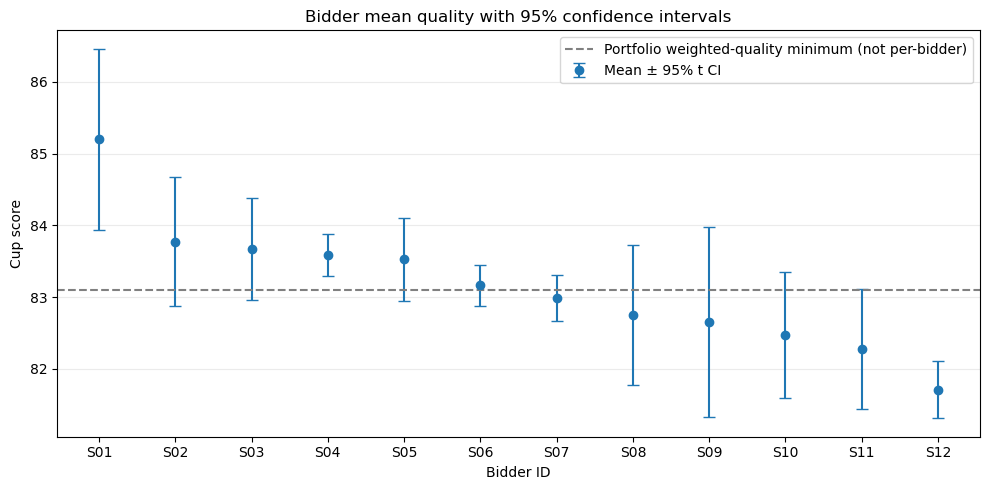

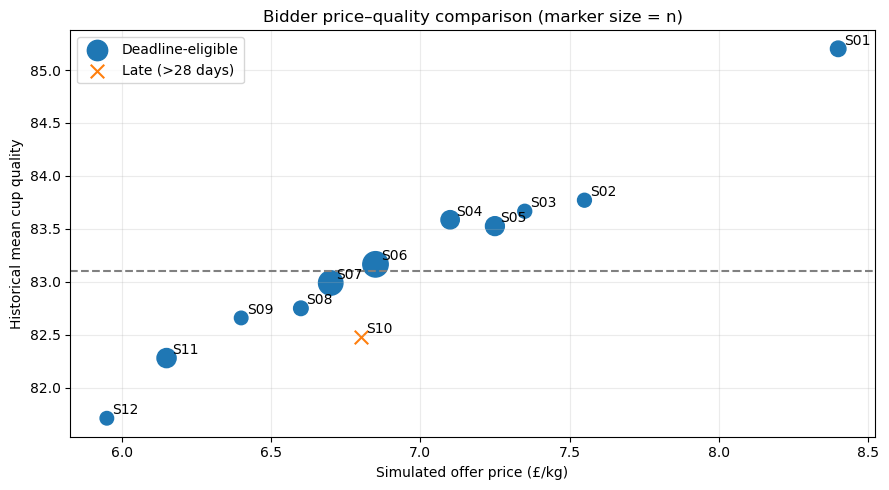


Part 1 finished: bidders table has 12 rows
All historical quality samples retained: 287
Missing processing methods: 57


In [3]:
# Read the supplied files and check for missing or inconsistent data
quality = pd.read_csv(
    DATA_DIR / REQUIRED_FILES[0],
    dtype={"sample_id": "string", "supplier_id": "string"},
)
offers = pd.read_csv(
    DATA_DIR / REQUIRED_FILES[1], dtype={"supplier_id": "string"}
)
scenarios = pd.read_csv(
    DATA_DIR / REQUIRED_FILES[2],
    dtype={"scenario": "string", "unavailable_supplier": "string"},
)
quality_samples = quality  # Existing group notebook compatibility.

required_columns = {
    "quality": {"sample_id", "supplier_id", "origin", "processing_method",
                "cup_points", "aroma", "flavour"},
    "offers": {"supplier_id", "fictional_name", "price_gbp_per_kg",
               "capacity_kg", "minimum_order_kg", "lead_time_days",
               "on_time_percent"},
    "scenarios": {"scenario", "demand_kg", "budget_gbp",
                  "minimum_weighted_quality", "deadline_days",
                  "maximum_supplier_share", "unavailable_supplier"},
}

for name, table in [("quality", quality), ("offers", offers),
                    ("scenarios", scenarios)]:
    missing_cols = required_columns[name] - set(table.columns)
    if missing_cols:
        raise ValueError(f"{name} is missing columns: {sorted(missing_cols)}")
    print(f"\n{name.upper()} — {table.shape[0]} rows, {table.shape[1]} columns")
    print("Missing by column:\n", table.isna().sum().to_string())
    print("Exact duplicate rows:", int(table.duplicated().sum()))

assert quality["sample_id"].notna().all() and quality["sample_id"].is_unique
assert quality["supplier_id"].notna().all()
assert quality["origin"].notna().all()
assert offers["supplier_id"].notna().all() and offers["supplier_id"].is_unique
assert scenarios["scenario"].notna().all() and scenarios["scenario"].is_unique
assert not quality.duplicated().any()
assert not offers.duplicated().any()
assert set(quality["supplier_id"]) == set(offers["supplier_id"])
assert set(scenarios["scenario"]) == {"Base", "Demand increase", "S01 unavailable"}
assert set(scenarios["unavailable_supplier"].dropna().astype(str)) <= set(offers["supplier_id"]) | {"None"}

# Audit numeric fields, without deleting historical samples.
for col, lower, upper in [("cup_points", 0, 100),
                          ("aroma", 0, 10), ("flavour", 0, 10)]:
    values = pd.to_numeric(quality[col], errors="coerce")
    assert values.notna().all(), f"Non-numeric/missing values in {col}"
    assert np.isfinite(values.to_numpy(dtype=float)).all(), col
    assert values.between(lower, upper).all(), f"Out-of-range {col}"
    if col == "cup_points":
        assert values.gt(0).all(), "Source requires positive cup scores"
    print(f"{col} range: {values.min():.2f} – {values.max():.2f}")

# processing_method is descriptive, not part of the required quality score.
missing_processing = (
    quality["processing_method"].isna()
    | quality["processing_method"].astype("string").str.strip().eq("").fillna(False)
)
print("Missing/blank processing methods:", int(missing_processing.sum()))

# Validate simulated numeric restrictions before relying on them.
offer_numbers = ["price_gbp_per_kg", "capacity_kg", "minimum_order_kg",
                 "lead_time_days", "on_time_percent"]
scenario_numbers = ["demand_kg", "budget_gbp", "minimum_weighted_quality",
                    "deadline_days", "maximum_supplier_share"]
assert offers[offer_numbers].notna().all().all()
assert scenarios[scenario_numbers].notna().all().all()
assert offers["price_gbp_per_kg"].gt(0).all()
assert offers["capacity_kg"].gt(0).all()
assert offers["minimum_order_kg"].ge(0).all()
assert offers["minimum_order_kg"].le(offers["capacity_kg"]).all()
assert offers["lead_time_days"].ge(0).all()
assert offers["on_time_percent"].between(0, 100).all()
assert scenarios["demand_kg"].gt(0).all()
assert scenarios["budget_gbp"].gt(0).all()
assert scenarios["deadline_days"].gt(0).all()
assert scenarios["minimum_weighted_quality"].between(0, 100).all()
assert scenarios["maximum_supplier_share"].between(0, 1).all()
assert (offers[["capacity_kg", "minimum_order_kg", "lead_time_days"]] % 1 == 0).all().all()
assert (scenarios[["demand_kg", "deadline_days"]] % 1 == 0).all().all()

# Summarise the historical quality scores by supplier
origin_per_bidder = quality.groupby("supplier_id")["origin"].nunique(dropna=False)
assert origin_per_bidder.eq(1).all(), "A bidder has multiple origin labels"

quality_tagged = quality.assign(processing_missing=missing_processing.astype(int))
quality_summary = (
    quality_tagged.groupby("supplier_id", as_index=False)
    .agg(
        n=("cup_points", "count"),
        mean_quality=("cup_points", "mean"),
        sd_quality=("cup_points", "std"),  # Sample SD (ddof=1).
        origin=("origin", "first"),
        missing_processing=("processing_missing", "sum"),
        mean_aroma=("aroma", "mean"),
        mean_flavour=("flavour", "mean"),
    )
)
assert quality_summary["n"].ge(2).all(), "t CI requires n >= 2"
assert quality_summary["n"].sum() == len(quality)

# Two-sided 95% Student-t confidence interval for each bidder mean.
quality_summary["se_quality"] = (
    quality_summary["sd_quality"] / np.sqrt(quality_summary["n"])
)
quality_summary["t_critical"] = t.ppf(0.975, quality_summary["n"] - 1)
quality_summary["ci95_margin"] = (
    quality_summary["t_critical"] * quality_summary["se_quality"]
)
quality_summary["ci95_low"] = (
    quality_summary["mean_quality"] - quality_summary["ci95_margin"]
)
quality_summary["ci95_high"] = (
    quality_summary["mean_quality"] + quality_summary["ci95_margin"]
)

# Weighted reconciliation: groups must reconstruct the original overall mean.
weighted_overall = (
    (quality_summary["n"] * quality_summary["mean_quality"]).sum()
    / quality_summary["n"].sum()
)
assert np.isclose(weighted_overall, quality["cup_points"].mean())

# Display the supplier-level quality statistics calculated above.
display(
    quality_summary[[
        "supplier_id", "n", "mean_quality", "sd_quality",
        "ci95_low", "ci95_high"
    ]].round(3)
)

# Add the supplier offers and check delivery eligibility
bidders = offers.merge(
    quality_summary, on="supplier_id", how="left",
    validate="one_to_one", indicator=True,
)
print("\nMerge results:\n", bidders["_merge"].value_counts().to_string())
assert len(bidders) == len(offers)
assert bidders["_merge"].eq("both").all()
bidders = bidders.drop(columns="_merge")

base_scen = scenarios.loc[scenarios["scenario"].eq("Base")].iloc[0]
bidders["eligible"] = bidders["lead_time_days"].le(
    int(base_scen["deadline_days"])
)
print("\nSupplier data for other group sections:")
print(bidders[["supplier_id", "n", "mean_quality", "sd_quality",
               "ci95_low", "ci95_high", "price_gbp_per_kg", "capacity_kg",
               "minimum_order_kg", "lead_time_days", "eligible"]]
      .sort_values("supplier_id").round(3).to_string(index=False))

# Plot the quality estimates and compare price against quality
ordered = bidders.sort_values("mean_quality", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
x_positions = np.arange(len(ordered))
ax.errorbar(
    x_positions, ordered["mean_quality"],
    yerr=ordered["ci95_margin"], fmt="o", capsize=4,
    label="Mean ± 95% t CI",
)
quality_floor = float(base_scen["minimum_weighted_quality"])
ax.axhline(quality_floor, color="gray", linestyle="--",
           label="Portfolio weighted-quality minimum (not per-bidder)")
ax.set_xticks(x_positions, ordered["supplier_id"])
ax.set_xlabel("Bidder ID")
ax.set_ylabel("Cup score")
ax.set_title("Bidder mean quality with 95% confidence intervals")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for eligibility, marker in [(True, "o"), (False, "x")]:
    group = bidders.loc[bidders["eligible"].eq(eligibility)]
    ax.scatter(
        group["price_gbp_per_kg"], group["mean_quality"],
        s=40 + group["n"] * 5, marker=marker,
        label="Deadline-eligible" if eligibility else "Late (>28 days)",
    )
for row in bidders.itertuples():
    ax.annotate(row.supplier_id,
                (row.price_gbp_per_kg, row.mean_quality),
                xytext=(4, 3), textcoords="offset points")
ax.axhline(quality_floor, color="gray", linestyle="--")
ax.set_xlabel("Simulated offer price (£/kg)")
ax.set_ylabel("Historical mean cup quality")
ax.set_title("Bidder price–quality comparison (marker size = n)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

OUTPUT_DIR.mkdir(exist_ok=True)
bidders.to_csv(OUTPUT_DIR / "bidders_quality_summary.csv", index=False)
print("\nPart 1 finished: bidders table has", len(bidders), "rows")
print("All historical quality samples retained:", len(quality))
print("Missing processing methods:", int(missing_processing.sum()))

# Section 2

**Baseline and Checker**

Name: Kim

### Description

Write the shared check_plan() function first

Lowest-price-first baseline for all 3 scenarios

Report which rules each baseline passes or fails


##### Check Plan Function

In [4]:
# Check whether an order plan meets the scenario requirements
# plan: quantity ordered from each supplier (including 0 kg orders)
# scen: demand, budget and other requirements for one scenario
def check_plan(plan, scen):
    supplier_ids = pd.Index(bidders["supplier_id"])

    # The plan must include all 12 suppliers exactly once
    if not isinstance(plan, pd.Series):
        raise ValueError("plan must be a pandas Series")
    if len(plan) != len(supplier_ids) or set(plan.index) != set(supplier_ids):
        raise ValueError("plan must include all supplier IDs")

    q = pd.to_numeric(plan.reindex(supplier_ids), errors="coerce")
    if q.isna().any() or not np.isfinite(q).all():
        raise ValueError("Invalid order quantities")

    # Match order quantities with supplier prices, quality and capacity
    b = bidders.set_index("supplier_id").loc[supplier_ids]

    demand = int(scen["demand_kg"])
    budget = float(scen["budget_gbp"])
    quality_min = float(scen["minimum_weighted_quality"])
    deadline = int(scen["deadline_days"])
    share_limit = float(scen["maximum_supplier_share"])
    unavailable = scen["unavailable_supplier"]

    if pd.isna(unavailable) or str(unavailable).strip().lower() == "none":
        unavailable = None

    # Calculate the cost and quality of the order plan
    used = q > 0
    total_kg = q.sum()
    cost = (q * b["price_gbp_per_kg"]).sum()

    if total_kg > 0:
        weighted_quality = (q * b["mean_quality"]).sum() / total_kg
        on_time_index = (q * b["on_time_percent"]).sum() / total_kg
    else:
        weighted_quality = float("nan")
        on_time_index = float("nan")

    # Check all ten conditions. Unused suppliers (0 kg) are allowed.
    checks = {
        "Nonnegative quantities": bool((q >= 0).all()),
        "Whole kilograms": bool((q % 1 == 0).all()),
        "Exact demand": bool(total_kg == demand),
        "Zero or minimum order": bool(((~used) | (q >= b["minimum_order_kg"])).all()),
        "Within supplier capacity": bool((q <= b["capacity_kg"]).all()),
        "Max supplier share": bool((q <= share_limit * demand).all()),
        "Delivery deadline": bool(((~used) | (b["lead_time_days"] <= deadline)).all()),
        "Unavailable supplier": bool(unavailable is None or q.loc[unavailable] == 0),
        "Within budget": bool(round(cost, 2) <= budget),
        "Weighted quality": bool(weighted_quality >= quality_min),
    }

    # Keep the numerical results separate from the pass/fail checks
    metrics = {
        "scenario": str(scen["scenario"]),
        "ordered_kg": float(total_kg),
        "demand_kg": demand,
        "total_cost_gbp": float(cost),
        "weighted_quality": float(weighted_quality),
        "quality_margin": float(weighted_quality - quality_min),
        "unused_budget_gbp": float(budget - cost),
        "maximum_supplier_share": float(q.max() / demand),
        "used_bidders": int(used.sum()),
        "weighted_on_time_index_pct": float(on_time_index),
        "feasible": all(checks.values()),
    }
    return metrics, checks

##### Lowest Price Function

In [5]:
# Build a price-first order plan, starting with minimum orders
# This is a simple baseline, not a cost or quality optimiser
def lowest_price_first(scen):
    demand = int(scen["demand_kg"])
    deadline = int(scen["deadline_days"])
    share_limit = int(float(scen["maximum_supplier_share"]) * demand)
    unavailable = scen["unavailable_supplier"]

    if pd.isna(unavailable) or str(unavailable).strip().lower() == "none":
        unavailable = None

    # Include all suppliers, even those with no order
    plan = pd.Series(0, index=bidders["supplier_id"], dtype=int, name="quantity_kg")
    candidates = bidders.sort_values(["price_gbp_per_kg", "supplier_id"])

    selected = []
    total_capacity = 0

    # Select enough eligible suppliers, starting with the cheapest
    for row in candidates.itertuples(index=False):
        if row.lead_time_days > deadline or row.supplier_id == unavailable:
            continue

        maximum = min(int(row.capacity_kg), share_limit)
        if maximum < row.minimum_order_kg:
            continue

        selected.append(row)
        total_capacity += maximum
        if total_capacity >= demand:
            break

    if total_capacity < demand:
        raise ValueError("Not enough supplier capacity")

    minimum_total = sum(row.minimum_order_kg for row in selected)
    if minimum_total > demand:
        raise ValueError("Minimum orders exceed demand")

    # Assign minimum orders first, avoiding a small leftover order
    for row in selected:
        plan.loc[row.supplier_id] = int(row.minimum_order_kg)

    remaining = demand - int(plan.sum())

    # Give the remaining demand to the cheapest suppliers first
    for row in selected:
        maximum = min(int(row.capacity_kg), share_limit)
        available = maximum - plan.loc[row.supplier_id]
        quantity = min(remaining, available)

        plan.loc[row.supplier_id] += quantity
        remaining -= quantity
        if remaining == 0:
            break

    return plan

##### Baseline Main

In [6]:
# Run the baseline and check every scenario
baseline_plans = {}
baseline_checks = {}
results = []
allocation_rows = []

for i in range(len(scenarios)):
    scen = scenarios.iloc[i]
    name = scen["scenario"]

    plan = lowest_price_first(scen)
    metrics, checks = check_plan(plan, scen)

    baseline_plans[name] = plan
    baseline_checks[name] = checks

    # Show which conditions are not met
    failed = []
    for rule in checks:
        if checks[rule] == False:
            failed.append(rule)
    metrics["failed_checks"] = ", ".join(failed) if failed else "None"
    results.append(metrics)

    # Save all 12 suppliers, including 0 kg orders
    for supplier_id, quantity in plan.items():
        allocation_rows.append({
            "scenario": name,
            "supplier_id": supplier_id,
            "quantity_kg": int(quantity),
        })


# Make tables for the three scenarios
baseline_summary = pd.DataFrame(results)
baseline_allocations = pd.DataFrame(allocation_rows)
allocation_table = pd.DataFrame(baseline_plans)
checks_table = pd.DataFrame(baseline_checks)

assert len(baseline_allocations) == len(scenarios) * len(bidders)
assert not baseline_allocations.duplicated(["scenario", "supplier_id"]).any()

print("BASELINE SUMMARY")
display(baseline_summary[[
    "scenario", "ordered_kg", "total_cost_gbp", "weighted_quality",
    "unused_budget_gbp", "feasible", "failed_checks"
]].round(4))

print("\nORDER ALLOCATION (kg)")
display(allocation_table)

print("\nCONSTRAINT CHECKS")
display(checks_table.replace({True: "PASS", False: "FAIL"}))

# These are baseline results, not the final sourcing decisions
baseline_summary.to_csv(OUTPUT_DIR / "baseline_summary.csv", index=False)
baseline_allocations.to_csv(
    OUTPUT_DIR / "baseline_allocations_NOT_FINAL.csv", index=False
)

BASELINE SUMMARY


,scenario,ordered_kg,total_cost_gbp,weighted_quality,unused_budget_gbp,feasible,failed_checks
0,Base,3000.0,18410.0,82.1538,5590.0,False,Weighted quality
1,Demand increase,3600.0,22142.0,82.1749,6658.0,False,Weighted quality
2,S01 unavailable,3000.0,18410.0,82.1538,5590.0,False,Weighted quality



ORDER ALLOCATION (kg)


,Base,Demand increase,S01 unavailable
supplier_id,,,
S01,0,0,0
S02,0,0,0
S03,0,0,0
S04,0,0,0
S05,0,0,0
S06,0,0,0
S07,0,0,0
S08,0,0,0
S09,800,1160,800



CONSTRAINT CHECKS


,Base,Demand increase,S01 unavailable
Nonnegative quantities,PASS,PASS,PASS
Whole kilograms,PASS,PASS,PASS
Exact demand,PASS,PASS,PASS
Zero or minimum order,PASS,PASS,PASS
Within supplier capacity,PASS,PASS,PASS
Max supplier share,PASS,PASS,PASS
Delivery deadline,PASS,PASS,PASS
Unavailable supplier,PASS,PASS,PASS
Within budget,PASS,PASS,PASS
Weighted quality,FAIL,FAIL,FAIL


# Section 3

**Optimisation**

Name: Joe

### Description

Integer program (PuLP) with a binary 'used' variable for the 100 kg minimum

Solve all 3 scenarios; verify each with check_plan()

Export sourcing_decisions.csv (36 rows)

#### Model inputs

In [7]:
# With gapRel=0, GapLimit means the gap reached zero, i.e. proven optimal.
# (This CBC build reports it as GapLimit rather than Optimal.)
OK_STATUSES = {pulp.LpSolveStatus.Optimal, pulp.LpSolveStatus.GapLimit}
QUALITY_MARGIN = 1e-6

# Dicts for the optimisation model
ids = bidders["supplier_id"].tolist()
price = dict(zip(bidders["supplier_id"], bidders["price_gbp_per_kg"]))
capacity = dict(zip(bidders["supplier_id"], bidders["capacity_kg"]))
min_order = dict(zip(bidders["supplier_id"], bidders["minimum_order_kg"]))
lead_time = dict(zip(bidders["supplier_id"], bidders["lead_time_days"]))
quality = dict(zip(bidders["supplier_id"], bidders["mean_quality"]))

#### Table builder

In [8]:
def build_table(data, columns):

    # Convert dicts and lists of dicts into a DataFrame
    if isinstance(data, (dict, list)):
        data = pd.DataFrame(data)

    if not isinstance(data, (pd.Series, pd.DataFrame)):
        raise TypeError("data must be a pandas Series, DataFrame, dict or list of dicts")

    # Turn meaningful row labels (e.g. supplier_id, scenario) into a normal column.
    # A plain 0, 1, 2... index is dropped rather than turned into a column.
    has_default_index = (isinstance(data.index, pd.RangeIndex)
                         and data.index.name is None)
    table = data.reset_index(drop=has_default_index)
    if isinstance(table, pd.Series):
        table = table.to_frame()

    # Check one name has been given for every column
    if len(columns) != table.shape[1]:
        raise ValueError(
            f"Got {len(columns)} column names but the table has {table.shape[1]} "
            f"columns: {list(table.columns)}"
        )

    table.columns = columns
    return table

#### Optimisation Model

###### Explanation
- This model finds the optimised order for each scenario

In [9]:
def optimise_scenario(scen):

    # Retrieve requirements for the scenario
    demand = int(scen["demand_kg"])
    budget = float(scen["budget_gbp"])
    min_quality = float(scen["minimum_weighted_quality"])
    deadline = int(scen["deadline_days"])
    share_limit = float(scen["maximum_supplier_share"])
    unavailable = scen["unavailable_supplier"]
    if pd.isna(unavailable) or str(unavailable).strip().lower() == "none":
        unavailable = None


    # Which supplier are allowed in the model (checking both their availability and lead time)
    allowed_sup = {i: (lead_time[i] <= deadline and i != unavailable) for i in ids}
    max_kg = {i: min(capacity[i], int(share_limit * demand)) for i in ids}


    # Creates the model
    model = pulp.LpProblem("Coffee_Sourcing_Problem", pulp.LpMinimize)
    x = model.add_variable_dicts("kg", ids, lowBound=0, cat="Integer")
    y = model.add_variable_dicts("used", ids, lowBound=0, upBound=1, cat="Binary")

    model += pulp.lpSum([price[i] * x[i] for i in ids])
    model += pulp.lpSum([x[i] for i in ids]) == demand, "Demand"
    model += pulp.lpSum([price[i] * x[i] for i in ids]) <= budget, "Budget"


    # This constraint ensures that the weighted quality of the order meets the minimum requirement
    # An important thing to explain in the presentation (it changes how the model sees the quality, changing it from purely cost-centric)
    model += pulp.lpSum((quality[i] - min_quality - QUALITY_MARGIN) * x[i] for i in ids) >= 0, "Quality"


    # Loop to add the minimum orders, maximum orders and disallowed suppliers
    for i in ids:
        model += x[i] >= min_order[i] * y[i], f"Min_{i}"
        model += x[i] <= max_kg[i] * y[i], f"Max_{i}"
        if not allowed_sup[i]:
            model += y[i] == 0, f"NotAllowed_{i}"


    stats = model.solve(solver)

    if stats.status not in OK_STATUSES:
        raise RuntimeError(f"No proven optimal plan: {stats.status_str}")

    # Builds a pandas series
    plan = pd.Series({i: int(round(x[i].value())) for i in ids}, name="quantity_kg")
    plan.index.name = "supplier_id"

    return plan, stats.status_str

#### Run all scenarios

In [10]:
opt_plans = {}
opt_results = []

for s in scenarios["scenario"]:
    scen = scenarios.loc[scenarios["scenario"].eq(str(s))].iloc[0]
    plan, status = optimise_scenario(scen)
    metrics, checks = check_plan(plan, scen)

    # print(s)
    # print(status)
    # print("Feasible:", metrics["feasible"])
    # print("Cost:", metrics["total_cost_gbp"])

    opt_plans[s] = plan
    opt_results.append(metrics)


display(build_table(opt_plans, ["Supplier ID", "Base (kg)", "Demand increase (kg)", "S01 unavailable (kg)"]))

# Something to add!
# Create functions for each stage of the coding, note how adding more constaints can change the model and the results.

# Final task. Add on the comparisons and visualise them, this is something that will come across much better on the presentation.

# One last thing to add!
# A choice for which restriction to use from the start.

,Supplier ID,Base (kg),Demand increase (kg),S01 unavailable (kg)
0,S01,150,319,0
1,S02,0,0,0
2,S03,0,0,0
3,S04,1200,1200,1200
4,S05,0,0,0
5,S06,0,0,0
6,S07,0,0,638
7,S08,0,0,0
8,S09,1200,1196,1162
9,S10,0,0,0


#### Export file and Summaries

In [11]:
# Summary of the optimised plans (one row per scenario)
opt_summary = pd.DataFrame(opt_results)

assert len(opt_summary) == len(scenarios), "Expected one row per scenario"
assert opt_summary["feasible"].all(), "An optimised plan fails a rule - check before exporting"

print("OPTIMISED SUMMARY")
display(build_table(
    opt_summary[[
        "scenario",
        "ordered_kg",
        "total_cost_gbp",
        "weighted_quality",
        "quality_margin",
        "unused_budget_gbp", 
        "used_bidders",
        "feasible"
        ]],
        ["Scenario",
         "Ordered (kg)",
         "Total cost (£)",
         "Weighted quality",
         "Quality margin",
         "Unused budget (£)",
         "Bidders used",
         "Feasible"]
))

opt_summary.to_csv(OUTPUT_DIR / "optimised_summary.csv", index=False)


# Build the 36-row decisions table: every bidder in every scenario, zeros included
# Same pattern as Kim's allocation_rows in Section 2
decision_rows = []

for name, plan in opt_plans.items():
    for supplier_id, quantity in plan.items():
        decision_rows.append({
            "scenario": name,
            "supplier_id": supplier_id,
            "quantity_kg": int(quantity),
        })

decisions = pd.DataFrame(decision_rows)

# Save the final submission file
decisions_path = OUTPUT_DIR / "sourcing_decisions.csv"
decisions.to_csv(decisions_path, index=False)

# Reload the file and check it meets the brief
reloaded = pd.read_csv(decisions_path, dtype={"scenario": "string", "supplier_id": "string"})

assert len(reloaded) == len(scenarios) * len(bidders), "Expected 36 rows"
assert list(reloaded.columns) == ["scenario", "supplier_id", "quantity_kg"]
assert set(reloaded["scenario"]) == set(scenarios["scenario"]), "Scenario names must match exactly"
assert not reloaded.duplicated(["scenario", "supplier_id"]).any()

totals = reloaded.groupby("scenario")["quantity_kg"].sum()
demand_by_scen = scenarios.set_index("scenario")["demand_kg"]
assert (totals == demand_by_scen.loc[totals.index]).all(), "Totals must equal demand"

print("Saved:", decisions_path.resolve())
print("Rows:", len(reloaded))

display(build_table(totals, ["Scenario", "Total"]))

OPTIMISED SUMMARY


,Scenario,Ordered (kg),Total cost (£),Weighted quality,Quality margin,Unused budget (£),Bidders used,Feasible
0,Base,3000.0,20227.50,83.100036,0.000036,3772.50,4,True
1,Demand increase,3600.0,24296.75,83.100048,0.000048,4503.25,4,True
2,S01 unavailable,3000.0,20231.40,83.100041,0.000041,3768.60,3,True


Saved: C:\Users\marty\Downloads\results\sourcing_decisions.csv
Rows: 36


,Scenario,Total
0,Base,3000
1,Demand increase,3600
2,S01 unavailable,3000


#### Comparisons

,scenario,total_cost_gbp_base,weighted_quality_base,feasible_base,total_cost_gbp_opt,weighted_quality_opt,feasible_opt,extra_cost_gbp,extra_cost_pct
0,Base,18410.0,82.15,False,20227.50,83.1,True,1817.50,9.87
1,Demand increase,22142.0,82.17,False,24296.75,83.1,True,2154.75,9.73
2,S01 unavailable,18410.0,82.15,False,20231.40,83.1,True,1821.40,9.89


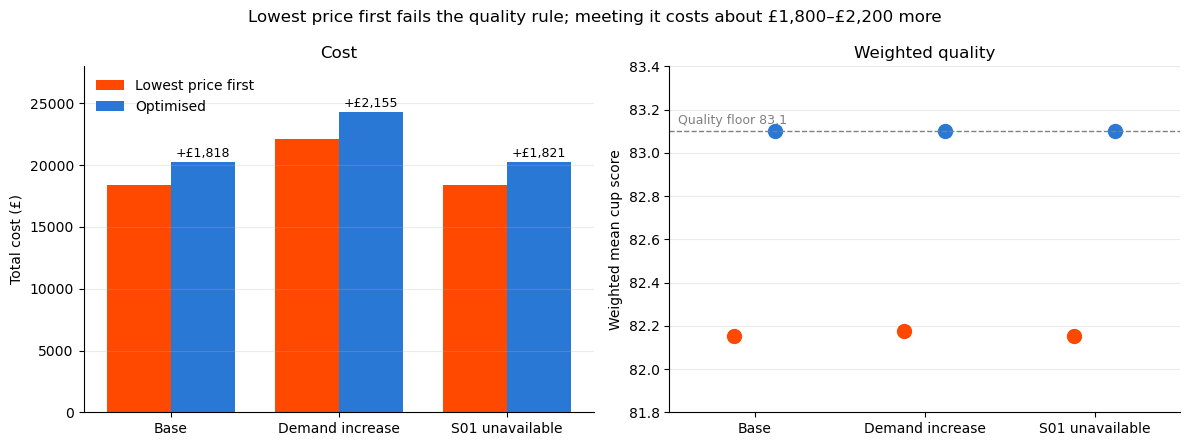

Figure saved in Results as 'baseline_vs_optimised.png'


In [12]:
# Baseline vs optimised, one row per scenario (Workshop 2, Exercise 5: merge on a shared key)
comparison = baseline_summary[["scenario", "total_cost_gbp", "weighted_quality", "feasible"]].merge(
    opt_summary[["scenario", "total_cost_gbp", "weighted_quality", "feasible"]],
    on="scenario", suffixes=("_base", "_opt"), validate="one_to_one",
)
comparison["extra_cost_gbp"] = comparison["total_cost_gbp_opt"] - comparison["total_cost_gbp_base"]
comparison["extra_cost_pct"] = 100 * comparison["extra_cost_gbp"] / comparison["total_cost_gbp_base"]

display(comparison.round(2))

# Two panels, one measure each (cost and quality have different scales, so never one shared chart)
BASE_COLOUR, OPT_COLOUR = "#ff4800", "#2a78d6"
names = comparison["scenario"]
pos = np.arange(len(names))
w = 0.38

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.bar(pos - w/2, comparison["total_cost_gbp_base"], w, color=BASE_COLOUR, label="Lowest price first")
ax1.bar(pos + w/2, comparison["total_cost_gbp_opt"], w, color=OPT_COLOUR, label="Optimised")
for p, extra in zip(pos, comparison["extra_cost_gbp"]):
    ax1.annotate(f"+£{extra:,.0f}", (p + w/2, comparison["total_cost_gbp_opt"].iloc[p]),
                 xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax1.set(xticks=pos, xticklabels=names, ylabel="Total cost (£)", title="Cost", ylim=(0, 28000))
ax1.legend(frameon=False, loc="upper left")

# Quality as dots, not bars: the axis does not start at zero, and bars would exaggerate the gap
ax2.plot(pos - 0.12, comparison["weighted_quality_base"], "o", markersize=10, color=BASE_COLOUR)
ax2.plot(pos + 0.12, comparison["weighted_quality_opt"], "o", markersize=10, color=OPT_COLOUR)
floor = float(scenarios["minimum_weighted_quality"].iloc[0])
ax2.axhline(floor, color="grey", linestyle="--", linewidth=1)
ax2.annotate(f"Quality floor {floor}", (pos[0] - 0.45, floor), xytext=(0, 5),
             textcoords="offset points", ha="left", fontsize=9, color="grey")
ax2.set(xticks=pos, xticklabels=names, ylabel="Weighted mean cup score",
        title="Weighted quality", ylim=(81.8, 83.4), xlim=(-0.5, len(names) - 0.5))

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Lowest price first fails the quality rule; meeting it costs about £1,800–£2,200 more")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "baseline_vs_optimised.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Figure saved in {OUTPUT_DIR} as 'baseline_vs_optimised.png'")

# Section 4

**Scenarios, Risk, and Reccomendations**

Name: Martyn

### Description

Compact three-scenario comparison table

Quality-margin robustness, e.g. lower CI bound or drop-one-bidder test

On-time performance and origin concentration

Recommendation; assemble slides

#### Three-scenario comparison

In [13]:
# Setup and the three-scenario comparison table

from scipy.stats import norm   #chance quality is really above 83.1

scenario_names = list(scenarios["scenario"])
bidder_info = bidders.set_index("supplier_id")   #look a supplier up by its ID

# stop early with a clear message if an earlier section hasn't been run
for name in scenario_names:
    assert name in opt_plans, f"No optimised plan for {name} - run Section 3 first"
    assert name in baseline_plans, f"No baseline plan for {name} - run Section 2 first"


def scenario_row(name):
    # grabs one row of the scenarios table for a given scenario name
    return scenarios.loc[scenarios["scenario"].eq(name)].iloc[0]


def plan_details(plan, scen):
    metrics, checks = check_plan(plan, scen)      # cost, quality and rule results come from Kim's checker
    used = plan[plan > 0]                         # suppliers that actually get an order
    origin_kg = used.groupby(bidder_info.loc[used.index, "origin"]).sum()
    origin_share = origin_kg / origin_kg.sum()    # share of the order coming from each country
    return {
        "metrics": metrics,
        "checks": checks,
        "used": used,
        "origin_share": origin_share,
        # if two origins tie for the biggest share, list both rather than picking one
        "top_origin": " / ".join(sorted(origin_share[origin_share >= origin_share.max() - 1e-9].index)),
        "top_origin_share": origin_share.max(),
    }


# work out the details for every scenario
opt_detail = {n: plan_details(opt_plans[n], scenario_row(n)) for n in scenario_names}
base_detail = {n: plan_details(baseline_plans[n], scenario_row(n)) for n in scenario_names}

# build the compact comparison table: column is scenario, row is measure
rows = {}
for n in scenario_names:
    s = scenario_row(n)
    o = opt_detail[n]["metrics"]
    b = base_detail[n]["metrics"]
    rows[n] = {
        "Demand (kg)": f"{o['demand_kg']:,}",
        "Budget (£)": f"{s['budget_gbp']:,.0f}",
        "Optimised cost (£)": f"{o['total_cost_gbp']:,.2f}",
        "Unused budget (£)": f"{o['unused_budget_gbp']:,.2f}",
        "Weighted quality": f"{o['weighted_quality']:.3f}",
        "Margin over minimum": f"{o['quality_margin']:+.5f}",
        "Bidders used": o["used_bidders"],
        "Largest bidder share": f"{o['maximum_supplier_share']:.0%}",
        "Weighted on-time (%)": f"{o['weighted_on_time_index_pct']:.1f}",
        "Largest origin": f"{opt_detail[n]['top_origin']} ({opt_detail[n]['top_origin_share']:.0%})",
        "Passes every rule?": "Yes" if o["feasible"] else "NO",
        "Baseline cost (£)": f"{b['total_cost_gbp']:,.2f}",
        "Baseline quality": f"{b['weighted_quality']:.3f}",
        "Baseline passes quality?": "Yes" if base_detail[n]["checks"]["Weighted quality"] else "NO - fails",
        "Extra cost vs baseline (£)": f"{o['total_cost_gbp'] - b['total_cost_gbp']:,.2f}",
    }

comparison = pd.DataFrame(rows)
comparison.index.name = "Measure"
print("THREE-SCENARIO COMPARISON (optimised plan, with baseline for reference)")
display(comparison)

OUTPUT_DIR.mkdir(exist_ok=True)
comparison.to_csv(OUTPUT_DIR / "section4_scenario_comparison.csv")

THREE-SCENARIO COMPARISON (optimised plan, with baseline for reference)


,Base,Demand increase,S01 unavailable
Measure,,,
Demand (kg),"3,000","3,600","3,000"
Budget (£),"24,000","28,800","24,000"
Optimised cost (£),"20,227.50","24,296.75","20,231.40"
Unused budget (£),"3,772.50","4,503.25","3,768.60"
Weighted quality,83.100,83.100,83.100
Margin over minimum,+0.00004,+0.00005,+0.00004
Bidders used,4,4,3
Largest bidder share,40%,33%,40%
Weighted on-time (%),93.0,93.0,92.8


#### Is the quality margin robust?

QUALITY ROBUSTNESS OF THE OPTIMISED PLANS (minimum required = 83.1)


,Scenario,Weighted quality,Margin,Std error,95% CI low,95% CI high,Worst case (all at CI low),Rough chance quality >= min
0,Base,83.1,0.0,0.254,82.602,83.598,82.266,0.5
1,Demand increase,83.1,0.0,0.233,82.644,83.556,82.246,0.5
2,S01 unavailable,83.1,0.0,0.240,82.630,83.570,82.404,0.5


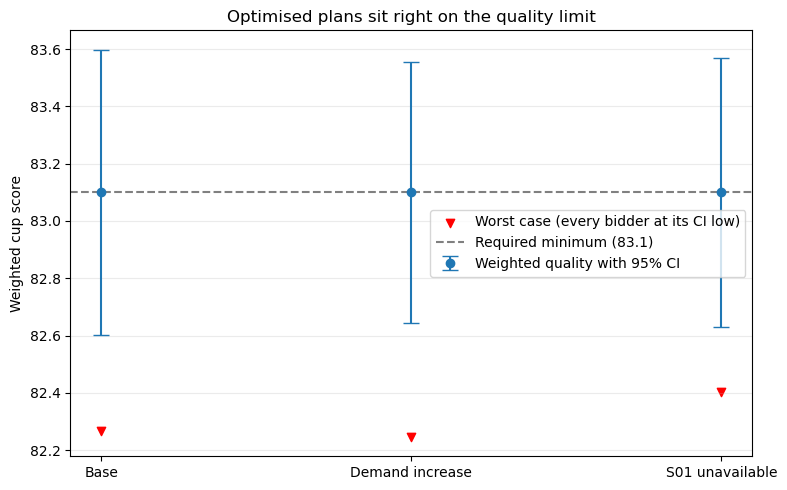

In [14]:
# How robust is the quality margin?
# The 83.1 rule uses each bidder's AVERAGE cup score from a small sample, so the true quality of a future delivery is uncertain.

def quality_uncertainty(plan, min_quality):
    # describes the uncertainty around the weighted quality of one plan
    used = plan[plan > 0]
    w = used / used.sum()                       # each bidder's share of the order
    info = bidder_info.loc[used.index]

    wq = (w * info["mean_quality"]).sum()       # weighted quality as the model sees it

    # worst case: EVERY bidder turns out as poor as the bottom of its own 95% CI
    worst_case = (w * info["ci95_low"]).sum()

    # more realistic: combine the bidders' standard errors (assumes bidders are independent)
    se = np.sqrt(((w * info["se_quality"]) ** 2).sum())

    return {
        "weighted_quality": wq,
        "margin": wq - min_quality,
        "std_error": se,
        "ci_low": wq - 1.96 * se,               # 95% interval for the weighted quality
        "ci_high": wq + 1.96 * se,
        "worst_case": worst_case,
        # chance that true weighted quality is at or above the minimum (normal approximation)
        "prob_meets_min": norm.cdf((wq - min_quality) / se),
    }


robust_rows = []
for n in scenario_names:
    min_q = float(scenario_row(n)["minimum_weighted_quality"])
    u = quality_uncertainty(opt_plans[n], min_q)
    robust_rows.append({
        "Scenario": n,
        "Weighted quality": u["weighted_quality"],
        "Margin": u["margin"],
        "Std error": u["std_error"],
        "95% CI low": u["ci_low"],
        "95% CI high": u["ci_high"],
        "Worst case (all at CI low)": u["worst_case"],
        "Rough chance quality >= min": u["prob_meets_min"],
    })
robustness = pd.DataFrame(robust_rows)

print("QUALITY ROBUSTNESS OF THE OPTIMISED PLANS (minimum required = 83.1)")
display(robustness.round(3))
robustness.to_csv(OUTPUT_DIR / "section4_quality_robustness.csv", index=False)

# chart: weighted quality with its 95% interval, against the 83.1 line
fig, ax = plt.subplots(figsize=(8, 5))
x_pos = np.arange(len(robustness))
ax.errorbar(
    x_pos, robustness["Weighted quality"],
    yerr=[robustness["Weighted quality"] - robustness["95% CI low"],
          robustness["95% CI high"] - robustness["Weighted quality"]],
    fmt="o", capsize=6, label="Weighted quality with 95% CI",
)
ax.scatter(x_pos, robustness["Worst case (all at CI low)"], marker="v", color="red",
           label="Worst case (every bidder at its CI low)")
ax.axhline(float(scenarios["minimum_weighted_quality"].iloc[0]), color="gray",
           linestyle="--", label="Required minimum (83.1)")
ax.set_xticks(x_pos, robustness["Scenario"])
ax.set_ylabel("Weighted cup score")
ax.set_title("Optimised plans sit right on the quality limit")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

#### Drop-one-bidder test and the price of a safety buffer

Sanity check passed: re-solve reproduces Joe's optimal costs.

DROP-ONE-BIDDER TEST


,Scenario,Bidder dropped,Feasible,New cost (£),Extra cost (£),Weighted quality,Rules passed
0,Base,S01,True,20231.40,3.90,83.1,True
1,Base,S04,True,20295.30,67.80,83.1,True
2,Base,S09,True,20280.30,52.80,83.1,True
3,Base,S11,True,20231.40,3.90,83.1,True
4,Demand increase,S01,True,24307.35,10.60,83.1,True
5,Demand increase,S04,True,24366.40,69.65,83.1,True
6,Demand increase,S09,True,24351.35,54.60,83.1,True
7,Demand increase,S11,True,24307.35,10.60,83.1,True
8,S01 unavailable,S04,True,20401.05,169.65,83.1,True
9,S01 unavailable,S07,True,20236.50,5.10,83.1,True



PRICE OF A QUALITY BUFFER (blank = no feasible plan)


,Scenario,Buffer,Cost (£),Extra cost (£),Rough chance quality >= min
0,Base,0.0,20227.50,0.00,0.500
1,Base,0.1,20458.75,231.25,0.653
2,Base,0.2,20689.80,462.30,0.782
3,Base,0.3,20921.05,693.55,0.875
4,Base,0.4,21154.20,926.70,0.938
5,Base,0.5,21386.40,1158.90,0.969
6,Base,0.6,21622.40,1394.90,0.989
7,Demand increase,0.0,24296.75,0.00,0.500
8,Demand increase,0.1,24574.00,277.25,0.666
9,Demand increase,0.2,24851.25,554.50,0.802


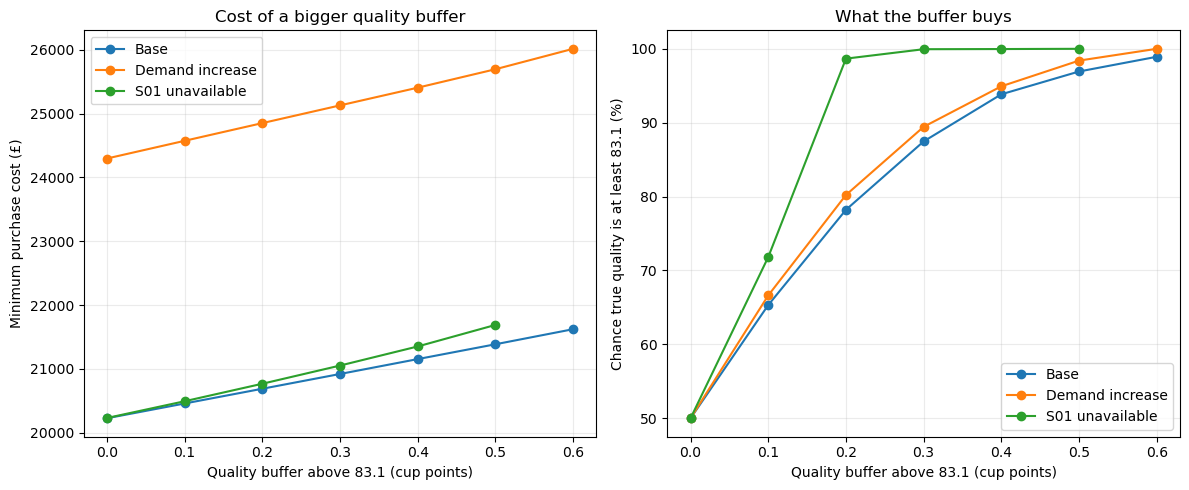

In [19]:
# Re-solving the model: drop-one-bidder test and the price of a safety buffer
# Joe's optimise_scenario() can't take extra options, so here is a copy of the same model with two knobs added.

def resolve(scen, exclude=(), min_quality=None):
    demand = int(scen["demand_kg"])
    budget = float(scen["budget_gbp"])
    deadline = int(scen["deadline_days"])
    share_limit = float(scen["maximum_supplier_share"])
    if min_quality is None:
        min_quality = float(scen["minimum_weighted_quality"])
    unavailable = scen["unavailable_supplier"]
    if pd.isna(unavailable) or str(unavailable).strip().lower() == "none":
        unavailable = None

    allowed = {i: (lead_time[i] <= deadline and i != unavailable and i not in exclude) for i in ids}
    max_kg = {i: min(capacity[i], int(share_limit * demand)) for i in ids}

    model = pulp.LpProblem("Coffee_Sourcing_Resolve", pulp.LpMinimize)
    x = model.add_variable_dicts("kg", ids, lowBound=0, cat="Integer")
    y = model.add_variable_dicts("used", ids, lowBound=0, upBound=1, cat="Binary")

    model += pulp.lpSum([price[i] * x[i] for i in ids])                      # minimise cost
    model += pulp.lpSum([x[i] for i in ids]) == demand, "Demand"
    model += pulp.lpSum([price[i] * x[i] for i in ids]) <= budget, "Budget"
    model += pulp.lpSum((quality[i] - min_quality - QUALITY_MARGIN) * x[i] for i in ids) >= 0, "Quality"
    for i in ids:
        model += x[i] >= min_order[i] * y[i], f"Min_{i}"
        model += x[i] <= max_kg[i] * y[i], f"Max_{i}"
        if not allowed[i]:
            model += y[i] == 0, f"NotAllowed_{i}"

    result = model.solve(solver)
    if result.status not in OK_STATUSES:
        return None                                # no feasible plan under these settings

    plan = pd.Series({i: int(round(x[i].value())) for i in ids}, name="quantity_kg")
    plan.index.name = "supplier_id"
    return plan


# sanity check: with no changes, my copy must give the same cost as Joe's plans
for n in scenario_names:
    s = scenario_row(n)
    same = resolve(s)
    assert same is not None
    assert np.isclose(check_plan(same, s)[0]["total_cost_gbp"],
                      check_plan(opt_plans[n], s)[0]["total_cost_gbp"]), f"{n}: re-solve differs from Section 3"
print("Sanity check passed: re-solve reproduces Joe's optimal costs.\n")


# Drop-one-bidder test
# For each bidder that the optimised plan uses, pretend it cannot deliver, re-optimise, and see what happens to cost and quality.
drop_rows = []
for n in scenario_names:
    s = scenario_row(n)
    base_cost = check_plan(opt_plans[n], s)[0]["total_cost_gbp"]
    for sid in opt_plans[n][opt_plans[n] > 0].index:
        alt = resolve(s, exclude=[sid])
        if alt is None:
            drop_rows.append({"Scenario": n, "Bidder dropped": sid, "Feasible": False,
                              "New cost (£)": np.nan, "Extra cost (£)": np.nan,
                              "Weighted quality": np.nan, "Rules passed": False})
        else:
            m, _ = check_plan(alt, s)              # check the replacement plan too
            drop_rows.append({"Scenario": n, "Bidder dropped": sid, "Feasible": True,
                              "New cost (£)": m["total_cost_gbp"],
                              "Extra cost (£)": m["total_cost_gbp"] - base_cost,
                              "Weighted quality": m["weighted_quality"],
                              "Rules passed": m["feasible"]})
drop_one = pd.DataFrame(drop_rows)
print("DROP-ONE-BIDDER TEST")
display(drop_one.round(2))
drop_one.to_csv(OUTPUT_DIR / "section4_drop_one_bidder.csv", index=False)


# Price of a quality buffer
# Ask for the average quality to beat 83.1 by a chosen margin, re-optimise, and record the extra cost and how likely the real quality is to reach 83.1.
BUFFERS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]     # extra cup points above the minimum

buffer_rows = []
for n in scenario_names:
    s = scenario_row(n)
    min_q = float(s["minimum_weighted_quality"])
    base_cost = check_plan(opt_plans[n], s)[0]["total_cost_gbp"]
    for buf in BUFFERS:
        alt = resolve(s, min_quality=min_q + buf)
        if alt is None:
            buffer_rows.append({"Scenario": n, "Buffer": buf, "Cost (£)": np.nan,
                                "Extra cost (£)": np.nan, "Rough chance quality >= min": np.nan})
            continue
        m, _ = check_plan(alt, s)
        u = quality_uncertainty(alt, min_q)
        buffer_rows.append({"Scenario": n, "Buffer": buf, "Cost (£)": m["total_cost_gbp"],
                            "Extra cost (£)": m["total_cost_gbp"] - base_cost,
                            "Rough chance quality >= min": u["prob_meets_min"]})
buffer_table = pd.DataFrame(buffer_rows)
print("\nPRICE OF A QUALITY BUFFER (blank = no feasible plan)")
display(buffer_table.round(3))
buffer_table.to_csv(OUTPUT_DIR / "section4_quality_buffer.csv", index=False)

# chart: cost against buffer, and confidence against buffer
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for n in scenario_names:
    part = buffer_table[buffer_table["Scenario"] == n]
    axes[0].plot(part["Buffer"], part["Cost (£)"], marker="o", label=n)
    axes[1].plot(part["Buffer"], part["Rough chance quality >= min"] * 100, marker="o", label=n)
axes[0].set_xlabel("Quality buffer above 83.1 (cup points)")
axes[0].set_ylabel("Minimum purchase cost (£)")
axes[0].set_title("Cost of a bigger quality buffer")
axes[1].set_xlabel("Quality buffer above 83.1 (cup points)")
axes[1].set_ylabel("Chance true quality is at least 83.1 (%)")
axes[1].set_title("What the buffer buys")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
plt.show()

#### On-time performance and origin concentration

ON-TIME AND ORIGIN RISK


,Scenario,Plan,Weighted on-time (%),Expected late kg,Lowest on-time bidder used (%),Origins used,Largest origin,Largest origin share,Origin HHI
0,Base,Optimised,92.950,211.50,91,4,Brazil / Colombia,0.400,0.345
1,Base,Baseline,91.133,266.00,90,3,Malawi,0.400,0.342
2,Demand increase,Optimised,92.951,253.75,91,4,Colombia,0.333,0.290
3,Demand increase,Baseline,91.244,315.20,90,3,Malawi,0.400,0.341
4,S01 unavailable,Optimised,92.787,216.38,92,2,Colombia,0.613,0.525
5,S01 unavailable,Baseline,91.133,266.00,90,3,Malawi,0.400,0.342



OPTIMISED PLANS: BIDDER DETAIL

Base


,kg,share,on_time_%,origin
supplier_id,,,,
S01,150,0.05,98,Ethiopia
S04,1200,0.40,93,Colombia
S09,1200,0.40,93,Brazil
S11,450,0.15,91,Taiwan



Demand increase


,kg,share,on_time_%,origin
supplier_id,,,,
S01,319,0.089,98,Ethiopia
S04,1200,0.333,93,Colombia
S09,1196,0.332,93,Brazil
S11,885,0.246,91,Taiwan



S01 unavailable


,kg,share,on_time_%,origin
supplier_id,,,,
S04,1200,0.400,93,Colombia
S07,638,0.213,92,Colombia
S09,1162,0.387,93,Brazil


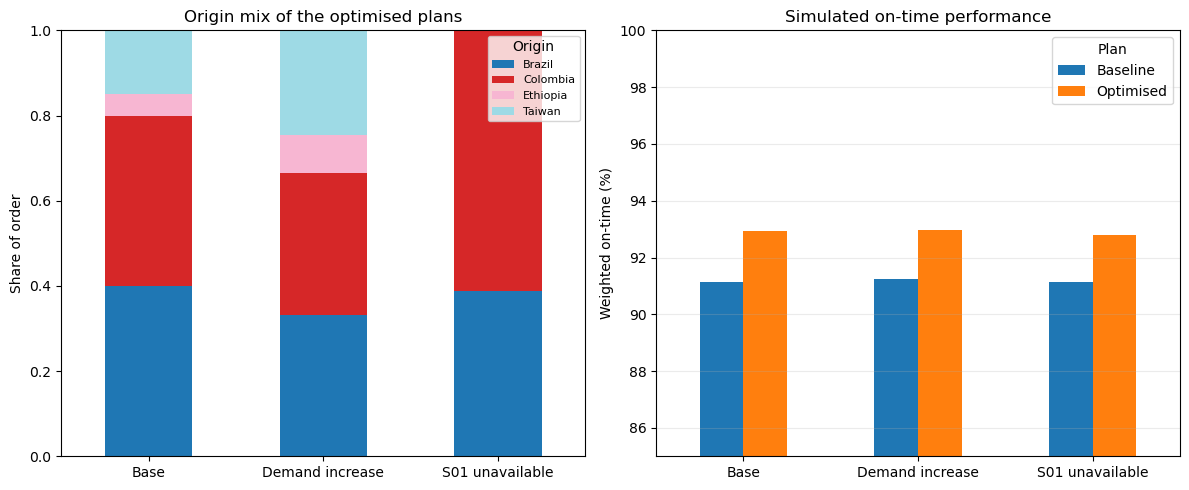

In [16]:
# On-time performance and origin concentration
# The on-time figures are SIMULATED, not real supplier records.

late_rows = []
for n in scenario_names:
    for label, detail, plans in [("Optimised", opt_detail[n], opt_plans[n]),
                                 ("Baseline", base_detail[n], baseline_plans[n])]:
        m = detail["metrics"]
        used = plans[plans > 0]
        # expected kg delivered late = kg ordered x (1 - on-time rate), added up over bidders
        late_kg = (used * (1 - bidder_info.loc[used.index, "on_time_percent"] / 100)).sum()
        late_rows.append({
            "Scenario": n, "Plan": label,
            "Weighted on-time (%)": m["weighted_on_time_index_pct"],
            "Expected late kg": late_kg,
            "Lowest on-time bidder used (%)": bidder_info.loc[used.index, "on_time_percent"].min(),
            "Origins used": len(detail["origin_share"]),
            "Largest origin": detail["top_origin"],
            "Largest origin share": detail["top_origin_share"],
            # HHI: 1 = everything from one origin, lower = more spread out
            "Origin HHI": (detail["origin_share"] ** 2).sum(),
        })
risk_table = pd.DataFrame(late_rows)
print("ON-TIME AND ORIGIN RISK")
display(risk_table.round(3))
risk_table.to_csv(OUTPUT_DIR / "section4_ontime_origin_risk.csv", index=False)

# which bidders, countries and delivery rates are in each optimised plan
print("\nOPTIMISED PLANS: BIDDER DETAIL")
for n in scenario_names:
    used = opt_plans[n][opt_plans[n] > 0]
    detail = pd.DataFrame({
        "kg": used,
        "share": used / used.sum(),
        "on_time_%": bidder_info.loc[used.index, "on_time_percent"],
        "origin": bidder_info.loc[used.index, "origin"],
    })
    print(f"\n{n}")
    display(detail.round(3))

# chart: origin mix of each optimised plan, plus on-time against baseline
origin_mix = pd.DataFrame({n: opt_detail[n]["origin_share"] for n in scenario_names}).fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
origin_mix.T.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20")
axes[0].set_ylabel("Share of order")
axes[0].set_xlabel("")
axes[0].set_title("Origin mix of the optimised plans")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Origin", fontsize=8)

ontime_chart = risk_table.pivot(index="Scenario", columns="Plan", values="Weighted on-time (%)").loc[scenario_names]
ontime_chart.plot(kind="bar", ax=axes[1])
axes[1].set_ylabel("Weighted on-time (%)")
axes[1].set_xlabel("")
axes[1].set_ylim(85, 100)
axes[1].set_title("Simulated on-time performance")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

#### Recommended plan

In [18]:
# Plan to recommend

CHOSEN_BUFFER = 0.4

rec_plans = {}
rec_rows = []
for n in scenario_names:
    s = scenario_row(n)
    min_q = float(s["minimum_weighted_quality"])
    plan = resolve(s, min_quality=min_q + CHOSEN_BUFFER)
    if plan is None:
        print(f"No feasible plan for {n} with a buffer of {CHOSEN_BUFFER} - try a smaller buffer")
        continue
    m, checks = check_plan(plan, s)
    assert m["feasible"], f"{n}: buffered plan fails a rule: {[k for k, v in checks.items() if not v]}"
    u = quality_uncertainty(plan, min_q)
    joe_cost = check_plan(opt_plans[n], s)[0]["total_cost_gbp"]
    rec_plans[n] = plan
    rec_rows.append({
        "Scenario": n,
        "Cost (£)": m["total_cost_gbp"],
        "Extra vs cheapest plan (£)": m["total_cost_gbp"] - joe_cost,
        "Extra vs cheapest plan (%)": 100 * (m["total_cost_gbp"] - joe_cost) / joe_cost,
        "Unused budget (£)": m["unused_budget_gbp"],
        "Weighted quality": m["weighted_quality"],
        "Rough chance quality >= min": u["prob_meets_min"],
        "Bidders used": m["used_bidders"],
        "Largest bidder share": m["maximum_supplier_share"],
        "Weighted on-time (%)": m["weighted_on_time_index_pct"],
    })

recommended = pd.DataFrame(rec_rows)
print(f"RECOMMENDED PLANS WITH A {CHOSEN_BUFFER}-POINT QUALITY BUFFER (all rules checked)")
display(recommended.round(3))

print("\nQuantities (kg) by bidder")
display(pd.DataFrame(rec_plans))

# save in the same layout as the decision file (scenario, supplier_id, quantity_kg)
buffered_rows = [{"scenario": n, "supplier_id": sid, "quantity_kg": int(q)}
                 for n, plan in rec_plans.items() for sid, q in plan.items()]
pd.DataFrame(buffered_rows).to_csv(OUTPUT_DIR / "sourcing_decisions_final.csv", index=False)
recommended.to_csv(OUTPUT_DIR / "section4_recommended_summary.csv", index=False)

RECOMMENDED PLANS WITH A 0.4-POINT QUALITY BUFFER (all rules checked)


,Scenario,Cost (£),Extra vs cheapest plan (£),Extra vs cheapest plan (%),Unused budget (£),Weighted quality,Rough chance quality >= min,Bidders used,Largest bidder share,Weighted on-time (%)
0,Base,21154.20,926.7,4.581,2845.80,83.5,0.938,4,0.400,93.869
1,Demand increase,25406.25,1109.5,4.566,3393.75,83.5,0.949,5,0.333,93.891
2,S01 unavailable,21352.20,1120.8,5.540,2647.80,83.5,1.000,4,0.400,94.318



Quantities (kg) by bidder


,Base,Demand increase,S01 unavailable
supplier_id,,,
S01,542,786,0
S02,0,0,0
S03,0,0,922
S04,1199,1200,1200
S05,0,0,103
S06,0,0,775
S07,103,105,0
S08,0,0,0
S09,1156,1200,0


#### Recommendation (DRAFT: check every number against the tables above before presenting)

- **Not the baseline.** Lowest-price-first is cheapest (£18,410 in the Base case) but its weighted quality is 82.15, below the 83.1 minimum, so it fails the quality rule in all three scenarios.
- **The optimised plans meet every rule at the lowest possible cost** (Base £20,227.50, Demand increase £24,296.75, S01 unavailable £20,231.40), roughly £1,800 to £2,150 more than the baseline.
- **The quality margin is not robust.** The optimised plans sit exactly on 83.1 (margin about +0.00004). With only 11 to 59 samples per bidder, the rough chance the true quality is at least 83.1 is about 50%, and if every bidder came in at the low end of its CI the plan would score about 82.2 to 82.4.
- **A 0.4-point buffer is affordable.** It costs about £927 to £1,121 more (4.6% to 5.5%), lifts the rough chance to around 94% or higher, and the plans still leave about £2,650 to £3,400 of budget unused.
- **Cost resilience is good.** Losing any one bidder in a plan adds at most about £170 (S04 in the S01-unavailable scenario).
- **Other risks.** Weighted on-time is about 93% (baseline about 91%). The Base plan puts 40% of volume with each of two single bidders (S04, Colombia; S09, Brazil), and the S01-unavailable plan is about 61% Colombian. These figures are simulated.
- **Decision for the group:** [cheapest plan / buffered plan: choose and justify]. **When it would change:** a buyer needing more certainty, more quality samples for the small-sample bidders, a tighter budget, or S04 or S09 becoming unavailable.